# classification de CNN _ Fruits Dataset

## Réalisé par Mme. OUHMIDA Asmae

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Step 1 : Dataset

In [2]:
img_height,img_width=32,32
batch_size=20
train_dataset=tf.keras.utils.image_dataset_from_directory("fruits/train",image_size=(img_height,img_width),batch_size=batch_size)
validation_dataset=tf.keras.utils.image_dataset_from_directory("fruits/validation",image_size=(img_height,img_width),batch_size=batch_size)
test_dataset=tf.keras.utils.image_dataset_from_directory("fruits/test",image_size=(img_height,img_width),batch_size=batch_size)

Found 460 files belonging to 3 classes.
Found 66 files belonging to 3 classes.
Found 130 files belonging to 3 classes.


# Visualisation des données

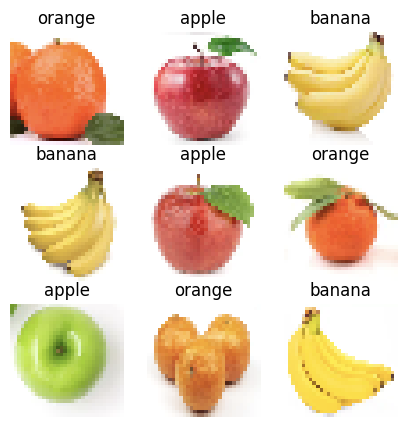

In [3]:
class_names = train_dataset.class_names
plt.figure(figsize=(5,5))
for image, labels in train_dataset.take(1):
    for i in range(9):
        plt.subplot(3,3,i+1)
        plt.imshow(image[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.show()

# Step 2: Création de modèle

In [4]:
model=tf.keras.Sequential(
    [
        tf.keras.layers.Rescaling(1./255),
        tf.keras.layers.Conv2D(32,(3,3),activation='relu'),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(32,(3,3),activation='relu'),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(32,(3,3),activation='relu'),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128,activation = "relu"),
        tf.keras.layers.Dense(3,activation='softmax')
    ]
)

In [5]:
# Step 3: paramétrage du modèle

In [6]:
model.compile(optimizer="adam",loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False)
        ,metrics=["accuracy"])

In [7]:
# Step 4: Training

In [8]:
model.fit(train_dataset,validation_data=validation_dataset,epochs=30,callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=6,restore_best_weights=True)])

Epoch 1/30


c:\Users\Hp\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


23/23 ━━━━━━━━━━━━━━━━━━━━ 5s 102ms/step - accuracy: 0.4261 - loss: 1.0579 - val_accuracy: 0.5758 - val_loss: 0.9587
Epoch 2/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.7478 - loss: 0.7068 - val_accuracy: 0.7727 - val_loss: 0.4918
Epoch 3/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.8565 - loss: 0.3872 - val_accuracy: 0.7879 - val_loss: 0.4209
Epoch 4/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.8652 - loss: 0.3280 - val_accuracy: 0.8788 - val_loss: 0.2433
Epoch 5/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9217 - loss: 0.2148 - val_accuracy: 0.9697 - val_loss: 0.1422
Epoch 6/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.9522 - loss: 0.1681 - val_accuracy: 0.9091 - val_loss: 0.2432
Epoch 7/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9630 - loss: 0.1400 - val_accuracy: 0.9848 - val_loss: 0.0867
Epoch 8/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9717 - loss: 0.1204 - val_accuracy: 0.9394 - val_loss: 0

In [9]:
# Step 5: Test

In [10]:
model.evaluate(test_dataset, verbose=2)

7/7 - 0s - 68ms/step - accuracy: 0.9385 - loss: 0.1384


[0.13844498991966248, 0.9384615421295166]

In [11]:
for images, labels in test_dataset.take(1):
    predictions = model.predict(images)
    predicted_classes = np.argmax(predictions, axis=1)
    for i in range(len(images)):
        print(f"Vrai : {class_names[labels[i]]}, Prédit : {class_names[predicted_classes[i]]}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 216ms/step
Vrai : orange, Prédit : orange
Vrai : banana, Prédit : banana
Vrai : banana, Prédit : banana
Vrai : orange, Prédit : orange
Vrai : banana, Prédit : banana
Vrai : banana, Prédit : banana
Vrai : apple, Prédit : apple
Vrai : apple, Prédit : apple
Vrai : orange, Prédit : orange
Vrai : apple, Prédit : banana
Vrai : banana, Prédit : banana
Vrai : apple, Prédit : apple
Vrai : orange, Prédit : orange
Vrai : apple, Prédit : orange
Vrai : banana, Prédit : banana
Vrai : apple, Prédit : apple
Vrai : orange, Prédit : orange
Vrai : orange, Prédit : orange
Vrai : apple, Prédit : apple
Vrai : banana, Prédit : banana


In [12]:
import json
from pathlib import Path

# Run this notebook from the streamLIT folder.
model.save('CNN_fruits.keras')
model.save('CNN_fruits.h5')
Path('class_names.json').write_text(json.dumps(class_names, indent=2), encoding='utf-8')


37